<a href="https://colab.research.google.com/github/Saranya782/ICTDSA/blob/main/Assignment_on_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Load dataset
df = pd.read_csv('House_Pricing.csv')

# 1. Structure and dimensions
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.head())

# 2. Data types & non-null counts
df.info()

# 3. Descriptive statistics
df.describe().T

Dataset Shape: 21613 rows, 21 columns

           ID Date House was Sold  Sale Price  No of Bedrooms  \
0  7129300520     14 October 2017    221900.0               3   
1  6414100192    14 December 2017    538000.0               3   
2  5631500400    15 February 2016    180000.0               2   
3  2487200875    14 December 2017    604000.0               4   
4  1954400510    15 February 2016    510000.0               3   

   No of Bathrooms  Flat Area (in Sqft)  Lot Area (in Sqft)  No of Floors  \
0             1.00               1180.0              5650.0           1.0   
1             2.25               2570.0              7242.0           2.0   
2             1.00                770.0             10000.0           1.0   
3             3.00               1960.0              5000.0           1.0   
4             2.00               1680.0              8080.0           1.0   

  Waterfront View No of Times Visited  ... Overall Grade  \
0              No                 NaN  ...     

,count,mean,std,min,25%,50%,75%,max
ID,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
Sale Price,21609.0,5.401984e+05,3.673890e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
No of Bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
No of Bathrooms,21609.0,2.114732e+00,7.701384e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
Flat Area (in Sqft),21604.0,2.079932e+03,9.184876e+02,2.900000e+02,1.429250e+03,1.910000e+03,2.550000e+03,1.354000e+04
Lot Area (in Sqft),21604.0,1.510776e+04,4.142827e+04,5.200000e+02,5.040000e+03,7.617500e+03,1.068825e+04,1.651359e+06
No of Floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
Overall Grade,21613.0,7.623467e+00,1.105439e+00,1.000000e+00,7.000000e+00,7.000000e+00,8.000000e+00,1.000000e+01
Area of the House from Basement (in Sqft),21610.0,1.788344e+03,8.279826e+02,2.900000e+02,1.190000e+03,1.560000e+03,2.210000e+03,9.410000e+03
Basement Area (in Sqft),21613.0,2.915090e+02,4.425750e+02,0.000000e+00,0.000000e+00,0.000000e+00,5.600000e+02,4.820000e+03


In [11]:
# Check and remove duplicate rows
dup_rows = df.duplicated().sum()
print(f"Duplicate rows detected: {dup_rows}")
if dup_rows > 0:
    df.drop_duplicates(inplace=True)

# Check and remove duplicate columns based on values
dup_cols = []
for i in range(len(df.columns)):
    col1 = df.columns[i]
    for j in range(i + 1, len(df.columns)):
        col2 = df.columns[j]
        if df[col1].equals(df[col2]):
            dup_cols.append(col2)

print(f"Duplicate columns detected: {dup_cols}")
if len(dup_cols) > 0:
    df.drop(columns=dup_cols, inplace=True)

Duplicate rows detected: 0
Duplicate columns detected: []


In [12]:
import numpy as np
import pandas as pd

# Load dataset
df = pd.read_csv('House_Pricing.csv')

# --- 1. Identify Missing Values ---
missing_series = df.isnull().sum()
missing_report = missing_series[missing_series > 0].to_frame(name='Missing Count')
missing_report['% Missing'] = (missing_report['Missing Count'] / len(df)) * 100
print("Features with Missing Values:")
print(missing_report)

# --- 2. Target Variable Imputation ---
target_col = 'Sale Price'
if df[target_col].isnull().sum() > 0:
    df[target_col] = df[target_col].fillna(df[target_col].median())

# --- 3. Numerical Columns Imputation (Median) ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
for col in num_cols:
    if df[col].isnull().sum() > 0:
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)
        print(f"Imputed numerical column '{col}' with median: {median_value}")

# --- 4. Categorical Columns Imputation (Mode) ---
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)
        print(f"Imputed categorical column '{col}' with mode: '{mode_value}'")

# --- 5. Verify No Missing Values Remain ---
print("\nTotal remaining missing values across dataset:", df.isnull().sum().sum())

Features with Missing Values:
                                           Missing Count  % Missing
Sale Price                                             4   0.018507
No of Bathrooms                                        4   0.018507
Flat Area (in Sqft)                                    9   0.041642
Lot Area (in Sqft)                                     9   0.041642
No of Times Visited                                19489  90.172581
Area of the House from Basement (in Sqft)              3   0.013881
Zipcode                                                1   0.004627
Latitude                                               1   0.004627
Longitude                                              1   0.004627
Living Area after Renovation (in Sqft)                 1   0.004627
Imputed numerical column 'No of Bathrooms' with median: 2.25
Imputed numerical column 'Flat Area (in Sqft)' with median: 1910.0
Imputed numerical column 'Lot Area (in Sqft)' with median: 7617.5
Imputed numerical column 'Ar

In [13]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Define target and identifier columns to exclude
target_col = 'Sale Price' if 'Sale Price' in df.columns else 'SalePrice'
exclude_cols = ['ID', target_col]

# Select numerical features
numerical_features = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in exclude_cols
]

print(f"Identified {len(numerical_features)} numerical features to scale.")

# Create a copy and fit StandardScaler
df_scaled = df.copy()
scaler = StandardScaler()

df_scaled[numerical_features] = scaler.fit_transform(df_scaled[numerical_features])

# Verify transformed statistics (Mean ≈ 0, Std ≈ 1)
print(df_scaled[numerical_features].describe().T[['mean', 'std', 'min', 'max']].head())

Identified 15 numerical features to scale.
                             mean       std       min        max
No of Bedrooms       2.419652e-16  1.000023 -3.624404  31.857929
No of Bathrooms     -1.578034e-16  1.000023 -2.746255   7.642662
Flat Area (in Sqft)  1.762138e-16  1.000023 -1.949142  12.479983
Lot Area (in Sqft)  -1.183526e-17  1.000023 -0.352125  39.504957
No of Floors        -5.260114e-17  1.000023 -0.915427   3.714405


In [14]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Create a copy for encoding
df_encoded = df.copy()

# Ensure missing values in categorical columns are handled (from Step 3)
df_encoded['No of Times Visited'] = df_encoded['No of Times Visited'].fillna('None')

# -------------------------------------------------------------
# 1. Label / Ordinal Encoding for Ordinal Features
# -------------------------------------------------------------
# 'Condition of the House' has a distinct natural ranking:
# Bad (1) < Okay (2) < Fair (3) < Good (4) < Excellent (5)
condition_rank = {
    'Bad': 1,
    'Okay': 2,
    'Fair': 3,
    'Good': 4,
    'Excellent': 5
}
df_encoded['Condition of the House'] = df_encoded['Condition of the House'].map(condition_rank)
print("Ordinal mapping applied to 'Condition of the House':")
print(df_encoded['Condition of the House'].value_counts().sort_index())

# -------------------------------------------------------------
# 2. One-Hot Encoding for Nominal Categories
# -------------------------------------------------------------
# 'Waterfront View' and 'No of Times Visited'
nominal_features = ['Waterfront View', 'No of Times Visited']

# drop_first=True prevents multicollinearity (dummy variable trap)
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

# -------------------------------------------------------------
# 3. Handling 'Date House was Sold'
# -------------------------------------------------------------
# Convert to datetime and extract temporal components (or drop if unneeded)
if 'Date House was Sold' in df_encoded.columns:
    df_encoded['Sale_Month'] = pd.to_datetime(df_encoded['Date House was Sold']).dt.month
    df_encoded['Sale_Year'] = pd.to_datetime(df_encoded['Date House was Sold']).dt.year
    df_encoded.drop(columns=['Date House was Sold'], inplace=True)

# -------------------------------------------------------------
# Verification
# -------------------------------------------------------------
print("\nNew columns created:")
encoded_cols = [c for c in df_encoded.columns if 'Waterfront' in c or 'Visited' in c or 'Condition' in c]
print(df_encoded[encoded_cols].head())

Ordinal mapping applied to 'Condition of the House':
Condition of the House
1       30
2      172
3    14031
4     5679
5     1701
Name: count, dtype: int64

New columns created:
   Condition of the House  Waterfront View_Yes  No of Times Visited_Once  \
0                       3                    0                         0   
1                       3                    0                         0   
2                       3                    0                         0   
3                       5                    0                         0   
4                       3                    0                         0   

   No of Times Visited_Thrice  No of Times Visited_Twice  
0                           0                          1  
1                           0                          1  
2                           0                          1  
3                           0                          1  
4                           0                          1  


--- Sale Price IQR Boundaries ---
Q1 (25th percentile): $322,000.00
Q3 (75th percentile): $645,000.00
IQR:                  $323,000.00
Lower Bound:          $-162,500.00 (bounded at minimum sale price)
Upper Bound:          $1,129,500.00

Number of outliers detected: 1159 (5.36%)
Dataset shape before removal: (21613, 21)
Dataset shape after removal:  (20454, 21)


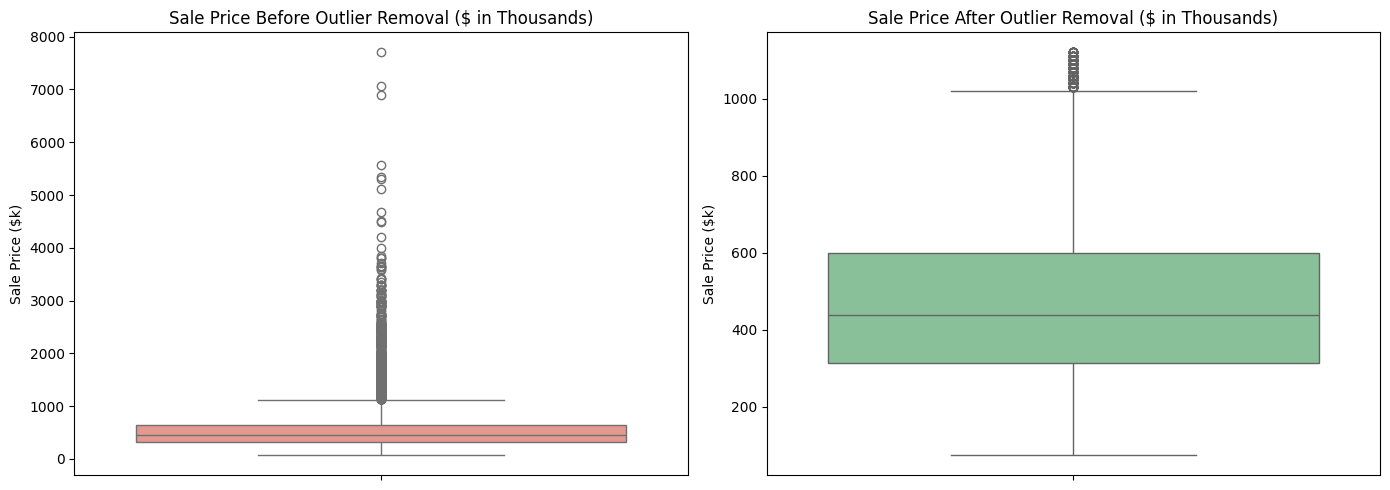

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify target variable
target_col = 'Sale Price' if 'Sale Price' in df.columns else 'SalePrice'

# 1. Calculate Quartiles and IQR for Sale Price
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print(f"--- {target_col} IQR Boundaries ---")
print(f"Q1 (25th percentile): ${Q1:,.2f}")
print(f"Q3 (75th percentile): ${Q3:,.2f}")
print(f"IQR:                  ${IQR:,.2f}")
print(f"Lower Bound:          ${lower_limit:,.2f} (bounded at minimum sale price)")
print(f"Upper Bound:          ${upper_limit:,.2f}")

# 2. Identify Outliers
outliers = df[(df[target_col] < lower_limit) | (df[target_col] > upper_limit)]
print(f"\nNumber of outliers detected: {len(outliers)} ({len(outliers) / len(df) * 100:.2f}%)")

# 3. Filter the Dataset to Keep Typical House Prices
df_cleaned = df[(df[target_col] >= lower_limit) & (df[target_col] <= upper_limit)].copy()
print(f"Dataset shape before removal: {df.shape}")
print(f"Dataset shape after removal:  {df_cleaned.shape}")

# 4. Boxplot Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before
sns.boxplot(ax=axes[0], y=df[target_col] / 1000, color='#f28e82')
axes[0].set_title(f'{target_col} Before Outlier Removal ($ in Thousands)')
axes[0].set_ylabel('Sale Price ($k)')

# After
sns.boxplot(ax=axes[1], y=df_cleaned[target_col] / 1000, color='#81c995')
axes[1].set_title(f'{target_col} After Outlier Removal ($ in Thousands)')
axes[1].set_ylabel('Sale Price ($k)')

plt.tight_layout()
plt.show()